# C2 block ablation: Input / CF / Delta

This is an experiment. It reads the cached folds and writes nothing to disk.

Each feature belongs to one of three blocks. Each block has a prob, an attribute and an embedding feature:

| Block | prob | attributes | embedding |
|---|---|---|---|
| **I**nput | C0 prob of x | attrs of x | C0 emb of x |
| **C**F | C0 prob of CF | attrs of CF | C0 emb of CF |
| **D**elta | prob(x) - prob(CF) | scaled attrs(x) - scaled attrs(CF) | emb(x) - emb(CF) |

Every config below is one combination of blocks, and all three feature types are used in each block.

Note: Delta = Input - CF, so I+C, I+D, C+D and I+C+D hold the same information.
Any difference between them comes from how easily the model can use a difference (trees find this much harder than an MLP).

Set `NO_PROB = True` to drop the three prob features from every block. What remains shows how much the attributes and embeddings add on their own.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit

sys.path.insert(0, "/zhome/d0/a/221493/thesis/final_experiment/code")
from c2_folds import load_folds, build_cf_source
from c2_train_attributes import feature_columns

from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from c2_msp import msp_standard, msp_threshold

DISEASES = ["effusion", "atelectasis", "cardiomegaly", "consolidation", "edema"]
DISEASE  = DISEASES[0]           # the loop sets this; single-disease cells (PCA curves etc.) use it as is

def c0_threshold(d):
    return float(open(f"/work3/s251710/thesis_results/C0_final/multilabel_ignore/{d}/threshold.txt").read())

T = c0_threshold(DISEASE)
print(f"MSP threshold for {DISEASE}: {T:.4f}")


K_MAX    = 10                 # CFs cached per test query (cached pairings exist for 1, 5, 10)
K_VALUES = [1, 5, 10]         # K's read off the same run: mean of the first k slots
CACHE    = "/work3/s251710/thesis_results/C2_final_results/block_ablation_cache"


SOURCE  = build_cf_source("knn", strategy="correct_cf")   # -> knn_correct_cf, K=1
MODELS  = ["MLP"]   # PyTorch MLP (the only model)
NO_PROB = True    # True: drop prob(x), prob(CF) and delta prob fom every block
K = 10

PCA_DIMS = {"attr": None, "emb": None}   # components per feature type; None = no PCA
RESIDUAL = False    # True: model = MSP + learned correction.  False: plain MLP
SIAMESE  = True     # True: one shared encoder h for the query and the CF (see "Models").  False: flat MLP

DEVICE  = "cpu"
if torch.cuda.is_available():   # shared node: take the GPU with the most free memory
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    DEVICE = f"cuda:{int(np.argmax(free))}"
    print(f"free GPU memory (GB): {[round(f / 1e9, 1) for f in free]}")
print("device:", DEVICE)

MSP threshold for effusion: 0.3932
free GPU memory (GB): [42.0]
device: cuda:0


## Feature blocks

In [2]:
def features(df, cols, block):
    """Return the prob, attribute and embedding features of one block."""
    d = DISEASE
    if block == "I":
        return [df[[f"{d}_prob"]].values, df[cols["attr"]].values, df[cols["emb"]].values]
    if block == "C":
        return [df[["cf_prob"]].values, df[cols["cf_attr"]].values, df[cols["cf_emb"]].values]
    if block == "D":
        return [df[["delta_prob"]].values, df[cols["delta"]].values,
                df[cols["emb"]].values - df[cols["cf_emb"]].values]

CONFIGS = ["I", "C", "D", "I+C","I+C+D"]
KINDS = ["prob", "attr", "emb"]          # the order features() returns them in

def fit_pcas(train, cols):
    """One PCA per (block, feature type), fit on this fold's training rows only."""
    pcas = {}
    for b in ["I", "C", "D"]:
        for kind, f in zip(KINDS, features(train, cols, b)):
            if PCA_DIMS.get(kind):
                print(f"fitting PCA for {b} {kind} ({f.shape[1]} -> {PCA_DIMS[kind]})")
                pcas[(b, kind)] = make_pipeline(StandardScaler(),
                                                PCA(PCA_DIMS[kind], random_state=42)).fit(f)
    return pcas

def X(df, cols, config, pcas={}):
    first = 1 if NO_PROB else 0          # prob is always the first feature of a block
    parts = []
    for b in config.split("+"):
        for kind, f in list(zip(KINDS, features(df, cols, b)))[first:]:
            parts.append(pcas[(b, kind)].transform(f) if (b, kind) in pcas else f)
    return np.hstack(parts).astype(np.float32)

def msp_base(df):
    """(n, 2): logit of adjusted MSP and the flag 'C0 predicted positive'."""
    p = df[f"{DISEASE}_prob"].values
    s = np.clip(msp_threshold(p, T), 1e-6, 1 - 1e-6)
    return np.column_stack([np.log(s / (1 - s)), p >= T]).astype(np.float32)

def pair_matrix(df, cols):
    """Siamese input: [attr(x), emb(x), attr(CF), emb(CF)] -- the same two feature types on
    both sides, so one encoder can read either. Which blocks the head sees is up to the config,
    inside the model; D is not an input here, it is h(x) - h(CF)."""
    return np.hstack([df[cols["attr"]].values, df[cols["emb"]].values,
                      df[cols["cf_attr"]].values, df[cols["cf_emb"]].values]).astype(np.float32)


## Models

The MLP runs in torch on CUDA when a GPU is available, otherwise on the CPU.

**Siamese (`SIAMESE = True`).** The flat MLP puts every block into one 64-unit layer (4,455 inputs
for I+C+D). The Siamese model instead has one encoder `h` per *image*: attributes -> 32 and
embedding -> 32, fused to a 32-d representation. The **same** `h` reads the query and its CF, so
the two land in one space and their difference means something:

| config | head input |
|---|---|
| I | h(x) |
| C | h(CF) |
| D | h(x) - h(CF) -- a learned delta, not the fixed scaled-attribute one |
| I+C | [h(x), h(CF)] |
| I+C+D | [h(x), h(CF), h(x) - h(CF)] |

The head is 16 ReLU -> 1. Inputs are standardised with one scaler shared by both sides
(`PairScaler`), fit on the query and CF rows stacked, so `h` sees them on the same scale.
Training (Adam, L2, class weight, patient-grouped early stopping) is unchanged.


In [3]:
class ResidualMLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(),
                               nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
        self.skip = nn.Linear(2, 1)
        if RESIDUAL:
            nn.init.zeros_(self.f[-1].weight); nn.init.zeros_(self.f[-1].bias)   # f starts at 0
            with torch.no_grad():
                self.skip.weight[:] = torch.tensor([[1.0, 0.0]])                  # skip starts = MSP logit
                self.skip.bias.zero_()

    def forward(self, x, s):
        out = self.f(x)
        if not RESIDUAL:
            return out
        return self.skip(s) + out


class SiameseMLP(nn.Module):
    """Shared encoder h on query and CF; the config picks what the head sees (see "Models")."""
    def __init__(self, n_attr, n_emb, config, d=32):
        super().__init__()
        self.n_attr, self.n_emb, self.parts = n_attr, n_emb, config.split("+")
        self.enc_attr = nn.Sequential(nn.Linear(n_attr, d), nn.ReLU())
        self.enc_emb  = nn.Sequential(nn.Linear(n_emb, d), nn.ReLU())
        self.fuse     = nn.Sequential(nn.Linear(2 * d, d), nn.ReLU())
        self.head     = nn.Sequential(nn.Linear(d * len(self.parts), 16), nn.ReLU(), nn.Linear(16, 1))
        self.skip = nn.Linear(2, 1)
        if RESIDUAL:
            nn.init.zeros_(self.head[-1].weight); nn.init.zeros_(self.head[-1].bias)
            with torch.no_grad():
                self.skip.weight[:] = torch.tensor([[1.0, 0.0]])
                self.skip.bias.zero_()

    def h(self, a, e):
        return self.fuse(torch.cat([self.enc_attr(a), self.enc_emb(e)], 1))

    def forward(self, x, s):
        na, ne = self.n_attr, self.n_emb
        hx = self.h(x[:, :na], x[:, na:na + ne])
        hc = self.h(x[:, na + ne:2 * na + ne], x[:, 2 * na + ne:])
        out = self.head(torch.cat([{"I": hx, "C": hc, "D": hx - hc}[p] for p in self.parts], 1))
        return self.skip(s) + out if RESIDUAL else out


class PairScaler:
    """One StandardScaler for both halves of a pair_matrix row, fit on query and CF rows stacked.
    Two separate scalers would put the query and its CF on different scales before the shared h."""
    def fit(self, X):
        self.half = X.shape[1] // 2
        self.sc = StandardScaler().fit(np.vstack([X[:, :self.half], X[:, self.half:]]))
        return self

    def transform(self, X):
        return np.hstack([self.sc.transform(X[:, :self.half]), self.sc.transform(X[:, self.half:])])


In [4]:
def fit_mlp(X_tr, y_tr, X_te, S_tr, S_te, groups, device, config=None, dims=None,
            epochs=500, patience=10, bs=200, seed=42):
    """Torch version of the sklearn MLP in c2_train_attributes: 64-32-16 ReLU, Adam,
    L2 1e-4, early stopping on val AUC (patience 10). The val split is 10% of the training
    rows, grouped by patient (`groups`), so no patient is on both sides of it.
    With SIAMESE, X is a pair_matrix, `dims` = (n_attr, n_emb) and `config` picks the head input."""
    torch.manual_seed(seed)
    scaler = (PairScaler() if SIAMESE else StandardScaler()).fit(X_tr)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
    X, Xte, y = to_t(scaler.transform(X_tr)), to_t(scaler.transform(X_te)), to_t(y_tr)
    S, Ste = to_t(S_tr), to_t(S_te)
    fit, val = next(GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=seed)
                    .split(X_tr, y_tr, groups))
    fit, val = torch.tensor(fit, device=device), torch.tensor(val, device=device)

    net = (SiameseMLP(*dims, config) if SIAMESE else ResidualMLP(X.shape[1])).to(device)

    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    pos_weight = torch.tensor((y_tr == 0).sum() / (y_tr ==1).sum(), dtype=torch.float32, device=device)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    net.eval()
    with torch.no_grad():
        p0 = net(X[val], S[val]).squeeze(1).cpu().numpy()
        
    #Early stopping now compares every epoch against the untrained model, which is exactly MSP.
    #If training never beats MSP on the validation rows, the model returns MSP unchange
    best = roc_auc_score(y_tr[val.cpu().numpy()], p0) if RESIDUAL else -1
    best_state, wait = {k: v.clone() for k, v in net.state_dict().items()}, 0
    for _ in range(epochs):
        net.train()
        for idx in fit[torch.randperm(len(fit), device=device)].split(bs):
            opt.zero_grad()
            loss_fn(net(X[idx], S[idx]).squeeze(1), y[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            p_val = net(X[val], S[val]).squeeze(1).cpu().numpy()
        score = roc_auc_score(y_tr[val.cpu().numpy()], p_val)
        if score > best + 1e-4:
            best, wait = score, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    with torch.no_grad():
        return torch.sigmoid(net(Xte, Ste).squeeze(1)).cpu().numpy().astype(np.float64)



def fit_predict(model, X_tr, y_tr, X_te, S_tr, S_te, groups, **kw):
    """Run on DEVICE; if the (shared) GPU is out of memory, redo the fit on the CPU."""
    try:
        return _fit_predict(model, X_tr, y_tr, X_te, S_tr, S_te, groups, DEVICE, **kw)
    except Exception as e:     # torch OutOfMemoryError
        if DEVICE == "cpu" or "memory" not in str(e).lower():
            raise
        print(f"  {model}: GPU out of memory -> CPU")
        torch.cuda.empty_cache()
        return _fit_predict(model, X_tr, y_tr, X_te, S_tr, S_te, groups, "cpu", **kw)



def _fit_predict(model, X_tr, y_tr, X_te, S_tr, S_te, groups, device, **kw):
    p = fit_mlp(X_tr, y_tr, X_te, S_tr, S_te, groups, device, **kw)
    if device != "cpu":
        torch.cuda.empty_cache()     # hand torch's cached GPU memory back
    return p


## 5-fold CV

In [5]:
OUT = "/zhome/d0/a/221493/thesis/block_ablation_results"
tag = f"K{K}" + ("_siam" if SIAMESE else "") + ("_res" if RESIDUAL else "") + ("_noprob" if NO_PROB else "")
# The Siamese model reads attributes + embeddings only: no prob input, no PCA.
assert not SIAMESE or (NO_PROB and not any(PCA_DIMS.values())), "SIAMESE needs NO_PROB=True and no PCA"

rows, msp_rows = [], []
for DISEASE in DISEASES:
    T = c0_threshold(DISEASE)
    print(f"\n===== {DISEASE}  (C0 threshold {T:.3f}) =====")
    preds = []                                                                       # <-- per-row predictions
    for fold in load_folds(DISEASE, SOURCE, cf_count=K):
        train = fold.train
        tests = [fold.test_slot(j) for j in range(K)]
        cols  = feature_columns(train, DISEASE)
        pcas  = fit_pcas(train, cols)
        y_tr, y_te = train["correct"].values, tests[0]["correct"].values
        S_tr = msp_base(train)
        S_te = np.vstack([msp_base(t) for t in tests])
        p0 = tests[0][f"{DISEASE}_prob"].values
        msp_rows.append({"disease": DISEASE, "fold": fold.index,
                         "MSP":          roc_auc_score(y_te, msp_standard(p0)),
                         "adjusted MSP": roc_auc_score(y_te, msp_threshold(p0, T))})
        pred = tests[0][["path", "correct", f"{DISEASE}_prob"]].assign(fold=fold.index)   # <--
        if SIAMESE:    # one input for every config; the config is applied inside the model
            P_tr = pair_matrix(train, cols)
            P_te = np.vstack([pair_matrix(t, cols) for t in tests])
        for config in CONFIGS:
            if SIAMESE:
                X_tr, X_te = P_tr, P_te
            else:
                X_tr = X(train, cols, config, pcas)
                X_te = np.vstack([X(t, cols, config, pcas) for t in tests])
            for model in MODELS:
                p   = fit_predict(model, X_tr, y_tr, X_te, S_tr, S_te, train["patient_id"].values,
                                  config=config, dims=(len(cols["attr"]), len(cols["emb"]))
                                  ).reshape(K, -1).mean(axis=0)
                auc = roc_auc_score(y_te, p)
                pred[f"{model}_{config}_prob"] = p                                   # <--
                rows.append({"disease": DISEASE, "fold": fold.index, "config": config,
                             "model": model, "K": K, "auc": auc})
                print(f"{DISEASE:<13} fold {fold.index}  {config:<6} {model}  K={K}  AUC={auc:.4f}")
        preds.append(pred)                                                           # <--

    # save this disease now, so a crash later keeps everything finished so far
    results = pd.DataFrame(rows)
    results[results.disease == DISEASE].to_csv(f"{OUT}/c2_block_ablation_{DISEASE}_{tag}.csv", index=False)
    pd.concat(preds, ignore_index=True).to_csv(                                      # <--
        f"{OUT}/c2_block_ablation_{DISEASE}_{tag}_predictions.csv", index=False)
    print(f"saved {OUT}/c2_block_ablation_{DISEASE}_{tag}[_predictions].csv")

msp = pd.DataFrame(msp_rows)
print(msp.groupby("disease")[["MSP", "adjusted MSP"]].mean().round(4))



===== effusion  (C0 threshold 0.393) =====
effusion      fold 0  I      MLP  K=10  AUC=0.7731
effusion      fold 0  C      MLP  K=10  AUC=0.6631
effusion      fold 0  D      MLP  K=10  AUC=0.7714
effusion      fold 0  I+C    MLP  K=10  AUC=0.7760
effusion      fold 0  I+C+D  MLP  K=10  AUC=0.7755
effusion      fold 1  I      MLP  K=10  AUC=0.7806
effusion      fold 1  C      MLP  K=10  AUC=0.6652
effusion      fold 1  D      MLP  K=10  AUC=0.7799
effusion      fold 1  I+C    MLP  K=10  AUC=0.7834
effusion      fold 1  I+C+D  MLP  K=10  AUC=0.7855
effusion      fold 2  I      MLP  K=10  AUC=0.7857
effusion      fold 2  C      MLP  K=10  AUC=0.6710
effusion      fold 2  D      MLP  K=10  AUC=0.7843
effusion      fold 2  I+C    MLP  K=10  AUC=0.7924
effusion      fold 2  I+C+D  MLP  K=10  AUC=0.7881
effusion      fold 3  I      MLP  K=10  AUC=0.7816
effusion      fold 3  C      MLP  K=10  AUC=0.6634
effusion      fold 3  D      MLP  K=10  AUC=0.7782
effusion      fold 3  I+C    MLP  K=10

## Results

In [6]:
summary = results.groupby(["config", "model"])["auc"].agg(["mean", "std"]).unstack("model")
summary = summary.reindex(CONFIGS)
summary.round(4)

,mean,std
model,MLP,MLP
config,,
I,0.8606,0.0590
C,0.8209,0.0935
D,0.8632,0.0607
I+C,0.8681,0.0595
I+C+D,0.8685,0.0594


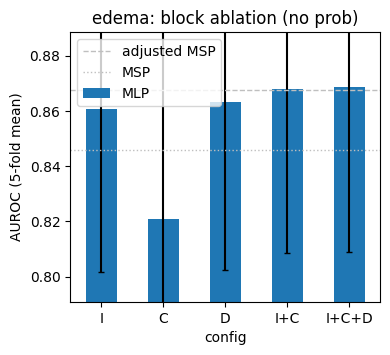

In [7]:
mean = results.groupby(["config", "model"])["auc"].mean().unstack("model").reindex(CONFIGS)
std  = results.groupby(["config", "model"])["auc"].std().unstack("model").reindex(CONFIGS)
mean.plot.bar(yerr=std, figsize=(4, 3.5), rot=0, capsize=2)
plt.ylim(mean.min().min() - 0.03, mean.max().max() + 0.02)
plt.ylabel("AUROC (5-fold mean)")
plt.title(f"{DISEASE}: block ablation" + (" (no prob)" if NO_PROB else ""))

ax = plt.gca()
ax.axhline(msp["adjusted MSP"].mean(), color="#BFBFBF", ls="--", lw=1, label="adjusted MSP")
ax.axhline(msp["MSP"].mean(),          color="#BFBFBF", ls=":",  lw=1, label="MSP")
ax.legend()

plt.show()

In [ ]:
# Flat vs Siamese on the same folds: mean AUROC over 5 folds per disease and config, from the
# saved CSVs of both runs. "I+C - I" is the number that matters -- does the counterfactual add
# more with the Siamese model, or does only I get better?
def load_run(tag):
    fs = [f"{OUT}/c2_block_ablation_{d}_{tag}.csv" for d in DISEASES]
    fs = [f for f in fs if os.path.exists(f)]
    return pd.concat([pd.read_csv(f) for f in fs]) if fs else None

suffix = ("_res" if RESIDUAL else "") + ("_noprob" if NO_PROB else "")
runs = {"flat": load_run(f"K{K}{suffix}"), "siamese": load_run(f"K{K}_siam{suffix}")}
cmp_tbl = {}
for name, r in runs.items():
    if r is None:
        print(f"{name}: no results for K={K}{suffix}"); continue
    t = r.groupby(["disease", "config"])["auc"].mean().unstack()[CONFIGS]
    t["I+C - I"], t["I+C+D - I"] = t["I+C"] - t["I"], t["I+C+D"] - t["I"]
    cmp_tbl[name] = t
cmp_tbl = pd.concat(cmp_tbl, axis=1)
if {"flat", "siamese"} <= set(cmp_tbl.columns.get_level_values(0)):
    for c in CONFIGS + ["I+C - I"]:
        cmp_tbl[("siamese - flat", c)] = cmp_tbl[("siamese", c)] - cmp_tbl[("flat", c)]
cmp_tbl.round(4)


In [8]:
from c2_msp import msp_standard, msp_threshold

# load past results and plot them
no_pca = pd.read_csv("/zhome/d0/a/221493/thesis/c2_block_ablation_atelectasis.csv")
no_pca_5k = pd.read_csv("/zhome/d0/a/221493/thesis/c2_block_ablation_atelectasis_5k_full.csv")
no_pca_10k = pd.read_csv("/zhome/d0/a/221493/thesis/c2_block_ablation_atelectasis_10k_full.csv")
no_pca_10k_residual = pd.read_csv("/zhome/d0/a/221493/thesis/c2_block_ablation_atelectasis_10k_full_res.csv")

# Plot the three results together. One plot, 3 bars per config, each bar is the mean of 5 folds, error bars are stddev.
mean_no_pca = no_pca.groupby(["config", "model"])["auc"].mean().unstack("model").reindex(CONFIGS)
std_no_pca  = no_pca.groupby(["config", "model"])["auc"].std().unstack("model").reindex(CONFIGS)
mean_no_pca_5k = no_pca_5k.groupby(["config", "model"])["auc"].mean().unstack("model").reindex(CONFIGS)
std_no_pca_5k  = no_pca_5k.groupby(["config", "model"])["auc"].std().unstack("model").reindex(CONFIGS)
mean_no_pca_10k = no_pca_10k.groupby(["config", "model"])["auc"].mean().unstack("model").reindex(CONFIGS)
std_no_pca_10k  = no_pca_10k.groupby(["config", "model"])["auc"].std().unstack("model").reindex(CONFIGS)
mean_no_pca_10k_residual = no_pca_10k_residual.groupby(["config", "model"])["auc"].mean().unstack("model").reindex(CONFIGS)
std_no_pca_10k_residual  = no_pca_10k_residual.groupby(["config", "model"])["auc"].std().unstack("model").reindex(CONFIGS)

plt.figure(figsize=(4, 4))
width = 0.2
x = np.arange(len(CONFIGS))
plt.bar(x - width/2, mean_no_pca["MLP"],   width, yerr=std_no_pca["MLP"],   label="MLPw",      capsize=2)
plt.bar(x + width/2, mean_no_pca_5k["MLP"], width, yerr=std_no_pca_5k["MLP"], label="MLPw(5k)", capsize=2)
plt.bar(x + 3*width/2, mean_no_pca_10k["MLP"], width, yerr=std_no_pca_10k["MLP"], label="MLPw(10k)", capsize=2)
plt.bar(x + 5*width/2, mean_no_pca_10k_residual["MLP"], width, yerr=std_no_pca_10k_residual["MLP"], label="MLPw(10k) + MSP", capsize=2)
plt.xticks(x, CONFIGS)
plt.ylim(0.7, 0.9)
plt.ylabel("AUROC (5-fold mean)")
plt.xlabel("Config")    
plt.title(f"{DISEASE}: block ablation")
plt.legend()

ax = plt.gca()
ax.axhline(msp["adjusted MSP"].mean(), color="#BFBFBF", ls="--", lw=1, label="adjusted MSP")
ax.axhline(msp["MSP"].mean(),          color="#BFBFBF", ls=":",  lw=1, label="MSP")
ax.legend()


plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/zhome/d0/a/221493/thesis/c2_block_ablation_atelectasis.csv'

---

### Evaluate the PCA

In [ ]:
from sklearn.decomposition import PCA

fold  = next(load_folds(DISEASE, SOURCE, cf_count=1))   # first fold only (~1.5 min)
train = fold.train
cols  = feature_columns(train, DISEASE)


In [ ]:
def cumulative_variance(f):
    """Share of variance kept by the first k components, for k = 1, 2, ..."""
    pca = PCA(random_state=42).fit(StandardScaler().fit_transform(f))
    return np.cumsum(pca.explained_variance_ratio_)

curves = {}
for block in ["I", "C", "D"]:
    _, attr, emb = features(train, cols, block)          # features() returns [prob, attr, emb]
    curves[f"{block} attr"] = cumulative_variance(attr)
    curves[f"{block} emb"]  = cumulative_variance(emb)

# components needed to keep 80 / 90 / 95 / 99 % of the variance
pd.DataFrame({name: {f"{int(q*100)}%": int(np.searchsorted(cum, q)) + 1
                     for q in [0.80, 0.90, 0.95, 0.99]}
              for name, cum in curves.items()}).T


,80%,90%,95%,99%
I attr,41,77,114,198
I emb,54,152,295,633
C attr,34,66,100,180
C emb,51,143,277,606
D attr,82,124,165,256
D emb,78,194,349,668


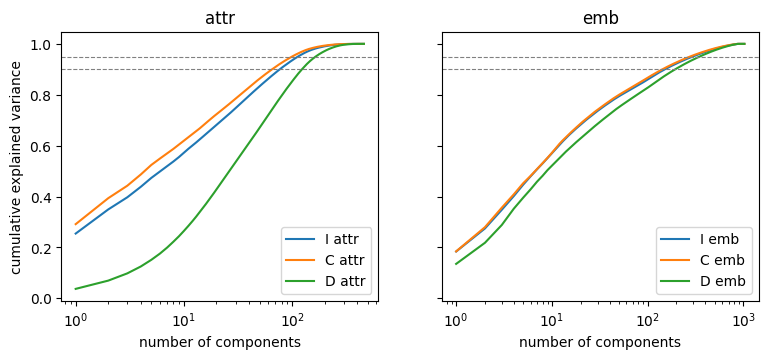

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, kind in zip(axes, ["attr", "emb"]):
    for name, cum in curves.items():
        if name.endswith(kind):
            ax.plot(np.arange(1, len(cum) + 1), cum, label=name)
    for q in [0.90, 0.95]:
        ax.axhline(q, color="grey", ls="--", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("number of components")
    ax.set_title(kind)
    ax.legend()
axes[0].set_ylabel("cumulative explained variance")
plt.show()
